# 02 — Class-conditioned diffusion fine-tuning with LoRA (learn 4 classes, later generate OCA only)

Fine-tunes a **pretrained Stable Diffusion** model on **all four classes** of the *training* patients,
with each image captioned by its diagnostic label. Generation (notebook 03) then uses the **OCA**
condition only. Nothing is trained from scratch; only small **LoRA** adapters (+ 4 class-token
embeddings in the improved mode) are learned.

Run this notebook **twice**:

| `MODE` | What it is | Used for |
|---|---|---|
| `"baseline"` | plain class prompts (`"... showing oral cancer ..."`) + class-balanced sampling | experiment **E3** |
| `"improved"` | + learnable **class tokens** (`<oca-lesion>`, `<opmd-lesion>`, ...) + a **class-contrastive denoising loss** that makes the OCA condition explicitly *different from OPMD* | experiment **E4** (your proposed method) |

**The class-contrastive loss (improved mode).** For each training image we also predict the noise
with a *wrong* class prompt (for OCA images, preferably **OPMD**). The model is rewarded when the
**correct** label explains the image better (lower denoising error) than the wrong one:

`L = L_denoise(correct) + λ · softplus( (L_correct − L_wrong) / (L_correct + L_wrong) / τ )`

This turns "four-class awareness" into an explicit training signal, not just a text label.
It is experimental: compare E4 with `USE_CONTRASTIVE=False` as an ablation.

**Leakage rule:** only **train**-split patients are used. Val/test images are never seen by the generator.

**Kaggle:** GPU **T4 x1** (P100 also fine), Internet **ON**. ~1.5–3 h for 3,000 steps at 512 px.

In [1]:
!pip uninstall -y -q torchao

In [2]:
# ============================================================
# 1. CONFIG   # @CONFIG
# ============================================================
from pathlib import Path

MODE = "improved"                 # "baseline" (E3) or "improved" (E4)

SPLIT_ROOT = Path("/kaggle/input/datasets/gokulkrishnabr/segmented-zenodo/train test vali zenodo")   # PLAIN split, not the oversampled one
OUT_DIR = Path(f"/kaggle/working/lora_oca_{MODE}")
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"   # later comparison: an SD 2.x / SDXL model (needs a bigger GPU)

RESOLUTION = 512
TRAIN_STEPS = 3000
BATCH_SIZE = 2 if MODE == "improved" else 4     # improved runs 2 UNet passes per image
GRAD_ACCUM = 2 if MODE == "improved" else 1     # -> same effective batch (4) in both modes
LR_UNET = 1e-4
LR_TOKENS = 5e-4
LR_WARMUP_STEPS = 100
LORA_RANK = 32
LORA_ALPHA = 32
LORA_TARGET_MODULES = ["to_k", "to_q", "to_v", "to_out.0"]
GRADIENT_CHECKPOINTING = True

# Improvement 1: class-balanced sampling (OCA is only ~4% of images).
# Probability that a training sample comes from each class (natural train share ~25/25/46/4 %).
CLASS_SAMPLING_PROBS = {"Healthy": 0.20, "Benign": 0.20, "OPMD": 0.25, "OCA": 0.35}
CAPTION_DROPOUT = 0.10            # 10% empty captions -> enables classifier-free guidance

# Improvement 3 (improved mode only)
USE_CLASS_TOKENS = MODE == "improved"
USE_CONTRASTIVE = MODE == "improved"
CONTRASTIVE_WEIGHT = 0.05
CONTRASTIVE_TAU = 0.1
CONTRASTIVE_START_FRAC = 0.3      # switch the contrastive term on after 30% of training
OCA_HARD_NEGATIVE_PROB = 0.5      # for OCA images, the "wrong" class is OPMD with this probability

SAVE_EVERY = 1000
PREVIEW_PER_CLASS = 2
LOG_EVERY = 50
SEED = 42
NUM_WORKERS = 2

In [3]:
# ============================================================
# DATA HELPERS -- read the patient-level split folders
#   <SPLIT_ROOT>/train/<Class>/*.png, val/..., test/...
#   (the output of your zenodo-patient-level-train-val-test-split notebook)
# ============================================================
import os, re, json, math, random, time, shutil, subprocess, sys, importlib
from pathlib import Path
import numpy as np
import pandas as pd

CLASSES = ["Benign", "Healthy", "OCA", "OPMD"]      # same alphabetical order as your earlier notebooks
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
OCA_IDX, OPMD_IDX = CLASS_TO_IDX["OCA"], CLASS_TO_IDX["OPMD"]
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}
_NAME_PATTERN = re.compile(r"^[A-Za-z]+-\d+")       # Zenodo names look like R-01-03, C-10-12-5


def patient_id_from_name(stem):
    """'R-01-03' -> 'R-01'  (same rule as the split notebook)."""
    parts = stem.split("-")
    return f"{parts[0]}-{parts[1]}" if len(parts) >= 2 else stem


def list_split(split_root, split):
    rows = []
    for c in CLASSES:
        d = Path(split_root) / split / c
        if not d.is_dir():
            raise FileNotFoundError(f"Missing folder: {d}  -- check SPLIT_ROOT")
        for p in sorted(d.iterdir()):
            if p.suffix.lower() in IMG_EXTS:
                rows.append({"path": str(p), "image_name": p.stem, "cls": c, "label": CLASS_TO_IDX[c],
                             "patient_id": patient_id_from_name(p.stem), "split": split, "synthetic": False})
    return pd.DataFrame(rows)


def load_split(split_root):
    dfs = {s: list_split(split_root, s) for s in ("train", "val", "test")}

    # 1) patient leakage check (hard stop)
    pats = {s: set(df.patient_id) for s, df in dfs.items()}
    for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
        overlap = pats[a] & pats[b]
        assert not overlap, f"Patient leakage between {a} and {b}: {sorted(overlap)[:10]}"

    # 2) warn if this looks like the AUGMENTED folder (oversampled copies) instead of the plain split
    odd = [n for df in dfs.values() for n in df.image_name if not _NAME_PATTERN.match(n)]
    if odd:
        print(f"WARNING: {len(odd)} file names don't look like Zenodo names (e.g. {odd[:3]}). "
              "If these are augmented/oversampled copies, point SPLIT_ROOT at the PLAIN patient-level "
              "split instead -- duplicated OCA copies make memorisation more likely and break patient IDs.")

    summary = pd.DataFrame({s: df.cls.value_counts().reindex(CLASSES).fillna(0).astype(int)
                            for s, df in dfs.items()})
    summary.loc["TOTAL"] = summary.sum()
    print("Images per split x class:")
    print(summary)
    print("Patients per split:", {s: len(p) for s, p in pats.items()})
    print("Patient leakage across train/val/test: NONE (checked)")
    return dfs


def ensure_package(module, pip_name=None):
    """Install a package only if it is missing (Kaggle needs Internet ON for this)."""
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or module])


def seed_everything(seed):
    import torch
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [4]:
# ============================================================
# 2. IMPORTS
# ============================================================
ensure_package("diffusers")
ensure_package("peft")
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms as T
from PIL import Image
import matplotlib.pyplot as plt
import diffusers, transformers, peft
from diffusers import (AutoencoderKL, UNet2DConditionModel, DDPMScheduler,
                       DPMSolverMultistepScheduler, StableDiffusionPipeline)
from transformers import CLIPTextModel, CLIPTokenizer
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
WEIGHT_DTYPE = torch.float16 if USE_AMP else torch.float32
print("Device:", DEVICE, "| torch", torch.__version__, "| diffusers", diffusers.__version__,
      "| transformers", transformers.__version__, "| peft", peft.__version__)
seed_everything(SEED)
OUT_DIR.mkdir(parents=True, exist_ok=True)

Device: cuda | torch 2.11.0+cu128 | diffusers 0.40.0 | transformers 5.16.1 | peft 0.20.0


In [5]:
# ============================================================
# 3. CLASS PROMPTS
#    baseline : natural-language class description
#    improved : description + a learnable class token (textual-inversion style)
# ============================================================
CLASS_PHRASES = {
    "Healthy": "healthy normal oral mucosa",
    "Benign": "a benign oral mucosal lesion",
    "OPMD": "an oral potentially malignant disorder such as leukoplakia or erythroplakia",
    "OCA": "oral cancer, an oral squamous cell carcinoma lesion",
}
CLASS_TOKENS = {"Healthy": "<healthy-mucosa>", "Benign": "<benign-lesion>",
                "OPMD": "<opmd-lesion>", "OCA": "<oca-lesion>"}
TOKEN_INIT_WORDS = {"Healthy": "healthy", "Benign": "benign", "OPMD": "leukoplakia", "OCA": "carcinoma"}
PROMPT_TEMPLATE = "a clinical intra-oral photograph of the oral cavity showing {phrase}"


def class_prompt(c, use_tokens=USE_CLASS_TOKENS):
    s = PROMPT_TEMPLATE.format(phrase=CLASS_PHRASES[c])
    # class token goes FIRST so it can never be cut off by CLIP's 77-token limit
    return f"{CLASS_TOKENS[c]}, {s}" if use_tokens else s


def sample_negative_class(c, rng):
    """'Wrong' class for the contrastive term; OCA prefers OPMD (the hardest confusion)."""
    if c == "OCA" and rng.random() < OCA_HARD_NEGATIVE_PROB:
        return "OPMD"
    return rng.choice([k for k in CLASSES if k != c])


for c in CLASSES:
    print(f"{c:8s} -> {class_prompt(c)}")

Benign   -> <benign-lesion>, a clinical intra-oral photograph of the oral cavity showing a benign oral mucosal lesion
Healthy  -> <healthy-mucosa>, a clinical intra-oral photograph of the oral cavity showing healthy normal oral mucosa
OCA      -> <oca-lesion>, a clinical intra-oral photograph of the oral cavity showing oral cancer, an oral squamous cell carcinoma lesion
OPMD     -> <opmd-lesion>, a clinical intra-oral photograph of the oral cavity showing an oral potentially malignant disorder such as leukoplakia or erythroplakia


In [6]:
# ============================================================
# 4. DATA: TRAIN PATIENTS ONLY, CLASS-BALANCED SAMPLING
# ============================================================
dfs = load_split(SPLIT_ROOT)
train_df = dfs["train"].reset_index(drop=True)      # val/test are never used here


class DiffusionImages(Dataset):
    def __init__(self, df, res):
        self.paths, self.labels = df["path"].tolist(), df["label"].astype(int).tolist()
        self.tf = T.Compose([T.Resize(res, interpolation=T.InterpolationMode.BICUBIC),
                             T.RandomCrop(res), T.RandomHorizontalFlip(),
                             T.ToTensor(), T.Normalize([0.5], [0.5])])   # conservative augmentation only

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]


counts = train_df["cls"].value_counts()
sample_w = train_df["cls"].map(lambda c: CLASS_SAMPLING_PROBS[c] / counts[c]).values
sampler = WeightedRandomSampler(torch.tensor(sample_w, dtype=torch.double),
                                num_samples=TRAIN_STEPS * BATCH_SIZE * GRAD_ACCUM + 64,
                                replacement=True, generator=torch.Generator().manual_seed(SEED))
train_dl = DataLoader(DiffusionImages(train_df, RESOLUTION), batch_size=BATCH_SIZE, sampler=sampler,
                      num_workers=NUM_WORKERS, drop_last=True)

exp_views = {c: CLASS_SAMPLING_PROBS[c] * TRAIN_STEPS * BATCH_SIZE * GRAD_ACCUM / counts[c] for c in CLASSES}
print("Expected times each training image is seen:", {c: round(v, 1) for c, v in exp_views.items()})
print("(High OCA re-use = memorisation risk -> notebook 03 checks for near-copies.)")

Images per split x class:
         train  val  test
cls                      
Benign     492  128   128
Healthy    481  123   125
OCA         76   16    37
OPMD       884  250   260
TOTAL     1933  517   550
Patients per split: {'train': 476, 'val': 119, 'test': 119}
Patient leakage across train/val/test: NONE (checked)
Expected times each training image is seen: {'Benign': np.float64(4.9), 'Healthy': np.float64(5.0), 'OCA': np.float64(55.3), 'OPMD': np.float64(3.4)}
(High OCA re-use = memorisation risk -> notebook 03 checks for near-copies.)


In [7]:
# ============================================================
# 5. LOAD PRETRAINED STABLE DIFFUSION + ADD LoRA (+ class tokens)
# ============================================================
tokenizer = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(MODEL_ID, subfolder="text_encoder")
vae = AutoencoderKL.from_pretrained(MODEL_ID, subfolder="vae")
unet = UNet2DConditionModel.from_pretrained(MODEL_ID, subfolder="unet")
noise_scheduler = DDPMScheduler.from_pretrained(MODEL_ID, subfolder="scheduler")

vae.requires_grad_(False)
text_encoder.requires_grad_(False)
unet.requires_grad_(False)

token_ids = {}
if USE_CLASS_TOKENS:
    n_added = tokenizer.add_tokens(list(CLASS_TOKENS.values()))
    assert n_added == len(CLASS_TOKENS), "class tokens already exist in the tokenizer?"
    text_encoder.resize_token_embeddings(len(tokenizer))
    emb = text_encoder.get_input_embeddings().weight
    with torch.no_grad():
        for c, tok in CLASS_TOKENS.items():
            tid = tokenizer.convert_tokens_to_ids(tok)
            init_ids = tokenizer(TOKEN_INIT_WORDS[c], add_special_tokens=False).input_ids
            emb[tid] = emb[init_ids].mean(0)          # start from a related word's meaning
            token_ids[c] = tid
    emb.requires_grad_(True)                          # only the 4 new rows are kept updated (see training loop)
    ORIG_EMB = emb.detach().clone()
    KEEP_FIXED = torch.ones(len(tokenizer), dtype=torch.bool)
    KEEP_FIXED[list(token_ids.values())] = False

for c in CLASSES:   # every prompt must fit in CLIP's 77-token window
    n_tok = len(tokenizer(class_prompt(c)).input_ids)
    if n_tok > tokenizer.model_max_length:
        print(f"WARNING: prompt for {c} has {n_tok} tokens (> {tokenizer.model_max_length}); its end will be cut off.")

lora_config = LoraConfig(r=LORA_RANK, lora_alpha=LORA_ALPHA, init_lora_weights="gaussian",
                         target_modules=LORA_TARGET_MODULES)
unet.add_adapter(lora_config)

unet.to(DEVICE, dtype=WEIGHT_DTYPE)                   # frozen base weights in fp16 on GPU
for p in unet.parameters():                           # trainable LoRA weights in fp32 for stable training
    if p.requires_grad:
        p.data = p.data.float()
vae.to(DEVICE, dtype=torch.float32)
text_encoder.to(DEVICE, dtype=torch.float32)
if USE_CLASS_TOKENS:
    ORIG_EMB, KEEP_FIXED = ORIG_EMB.to(DEVICE), KEEP_FIXED.to(DEVICE)
if GRADIENT_CHECKPOINTING:
    unet.enable_gradient_checkpointing()

lora_params = [p for p in unet.parameters() if p.requires_grad]
param_groups = [{"params": lora_params, "lr": LR_UNET, "weight_decay": 1e-2}]
if USE_CLASS_TOKENS:
    param_groups.append({"params": [text_encoder.get_input_embeddings().weight], "lr": LR_TOKENS, "weight_decay": 0.0})
optimizer = torch.optim.AdamW(param_groups)
lr_sched = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: min(1.0, (s + 1) / LR_WARMUP_STEPS))
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
print(f"Trainable LoRA parameters: {sum(p.numel() for p in lora_params):,}"
      + (f"  + {len(token_ids)} class-token embeddings" if USE_CLASS_TOKENS else ""))
print("Prediction type:", noise_scheduler.config.prediction_type)

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  492MB            

... (8 outputs left out)

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Trainable LoRA parameters: 6,377,472  + 4 class-token embeddings
Prediction type: epsilon


In [8]:
# ============================================================
# 6. HELPERS: text encoding, checkpoint saving, preview grids
# ============================================================
RUN_CONFIG = {
    "mode": MODE, "model_id": MODEL_ID, "resolution": RESOLUTION, "train_steps": TRAIN_STEPS,
    "batch_size": BATCH_SIZE, "grad_accum": GRAD_ACCUM, "lr_unet": LR_UNET, "lr_tokens": LR_TOKENS,
    "lora_rank": LORA_RANK, "lora_alpha": LORA_ALPHA, "lora_target_modules": LORA_TARGET_MODULES,
    "use_class_tokens": USE_CLASS_TOKENS, "use_contrastive": USE_CONTRASTIVE,
    "contrastive_weight": CONTRASTIVE_WEIGHT, "contrastive_tau": CONTRASTIVE_TAU,
    "contrastive_start_frac": CONTRASTIVE_START_FRAC, "oca_hard_negative_prob": OCA_HARD_NEGATIVE_PROB,
    "class_sampling_probs": CLASS_SAMPLING_PROBS, "caption_dropout": CAPTION_DROPOUT,
    "class_phrases": CLASS_PHRASES, "class_tokens": CLASS_TOKENS, "prompt_template": PROMPT_TEMPLATE,
    "classes": CLASSES, "seed": SEED, "n_train_images": len(train_df),
    "n_train_images_per_class": {c: int(counts[c]) for c in CLASSES},
}


def encode_prompts(prompts, grad):
    ids = tokenizer(prompts, padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt").input_ids.to(DEVICE)
    with torch.set_grad_enabled(grad):
        return text_encoder(ids)[0]


def save_adapter(path):
    path.mkdir(parents=True, exist_ok=True)
    lora_sd = {k: v.detach().cpu().float() for k, v in get_peft_model_state_dict(unet).items()}
    torch.save(lora_sd, path / "unet_lora.pt")
    if USE_CLASS_TOKENS:
        emb = text_encoder.get_input_embeddings().weight
        torch.save({tok: emb[tokenizer.convert_tokens_to_ids(tok)].detach().cpu().float()
                    for tok in CLASS_TOKENS.values()}, path / "class_tokens.pt")
    json.dump(RUN_CONFIG, open(path / "run_config.json", "w"), indent=2)


@torch.no_grad()
def preview(tag):
    unet.eval()
    pipe = StableDiffusionPipeline(vae=vae, text_encoder=text_encoder, tokenizer=tokenizer, unet=unet,
                                   scheduler=DPMSolverMultistepScheduler.from_config(noise_scheduler.config),
                                   safety_checker=None, feature_extractor=None, requires_safety_checker=False)
    pipe.set_progress_bar_config(disable=True)
    fig, axes = plt.subplots(PREVIEW_PER_CLASS, len(CLASSES), figsize=(3 * len(CLASSES), 3 * PREVIEW_PER_CLASS),
                             squeeze=False)
    for j, c in enumerate(CLASSES):
        g = torch.Generator(device=DEVICE).manual_seed(SEED)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            imgs = pipe([class_prompt(c)] * PREVIEW_PER_CLASS, num_inference_steps=25, guidance_scale=6.0,
                        height=RESOLUTION, width=RESOLUTION, generator=g).images
        for i, im in enumerate(imgs):
            axes[i, j].imshow(im); axes[i, j].axis("off")
        axes[0, j].set_title(c)
    plt.suptitle(f"{MODE} - {tag}")
    plt.tight_layout(); fig.savefig(OUT_DIR / f"preview_{tag}.png", dpi=110); plt.show()
    unet.train()

step    50/3000  loss 0.1225  denoise 0.1225  contrast 0.0000  (1.8 min)
step   100/3000  loss 0.1269  denoise 0.1269  contrast 0.0000  (3.7 min)
step   150/3000  loss 0.1193  denoise 0.1193  contrast 0.0000  (5.7 min)
step   200/3000  loss 0.1029  denoise 0.1029  contrast 0.0000  (7.8 min)
step   250/3000  loss 0.1102  denoise 0.1102  contrast 0.0000  (9.8 min)
step   300/3000  loss 0.1030  denoise 0.1030  contrast 0.0000  (11.9 min)
step   350/3000  loss 0.1253  denoise 0.1253  contrast 0.0000  (13.9 min)
step   400/3000  loss 0.1161  denoise 0.1161  contrast 0.0000  (15.9 min)
step   450/3000  loss 0.1021  denoise 0.1021  contrast 0.0000  (18.0 min)
step   500/3000  loss 0.1068  denoise 0.1068  contrast 0.0000  (20.0 min)
step   550/3000  loss 0.1287  denoise 0.1287  contrast 0.0000  (22.1 min)
step   600/3000  loss 0.1313  denoise 0.1313  contrast 0.0000  (24.1 min)
step   650/3000  loss 0.1234  denoise 0.1234  contrast 0.0000  (26.1 min)
step   700/3000  loss 0.1347  denoise 0.134

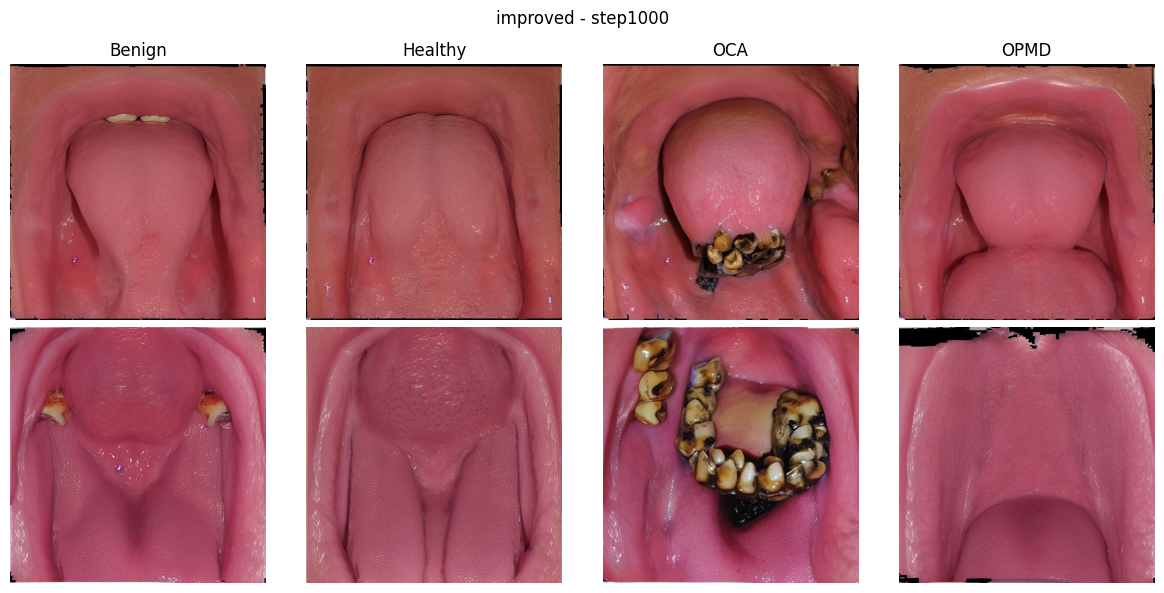

step  1050/3000  loss 0.1619  denoise 0.1274  contrast 0.6898  (46.0 min)
step  1100/3000  loss 0.1623  denoise 0.1278  contrast 0.6893  (48.9 min)
step  1150/3000  loss 0.1429  denoise 0.1103  contrast 0.6524  (51.9 min)
step  1200/3000  loss 0.1401  denoise 0.1061  contrast 0.6811  (54.9 min)
step  1250/3000  loss 0.1432  denoise 0.1091  contrast 0.6804  (57.9 min)
step  1300/3000  loss 0.1377  denoise 0.1033  contrast 0.6878  (60.8 min)
step  1350/3000  loss 0.1459  denoise 0.1121  contrast 0.6771  (63.8 min)
step  1400/3000  loss 0.1565  denoise 0.1224  contrast 0.6810  (66.8 min)
step  1450/3000  loss 0.1524  denoise 0.1183  contrast 0.6809  (69.8 min)
step  1500/3000  loss 0.1431  denoise 0.1095  contrast 0.6726  (72.7 min)
step  1550/3000  loss 0.1580  denoise 0.1239  contrast 0.6812  (75.7 min)
step  1600/3000  loss 0.1376  denoise 0.1029  contrast 0.6941  (78.7 min)
step  1650/3000  loss 0.1528  denoise 0.1187  contrast 0.6809  (81.7 min)
step  1700/3000  loss 0.1539  denoise 

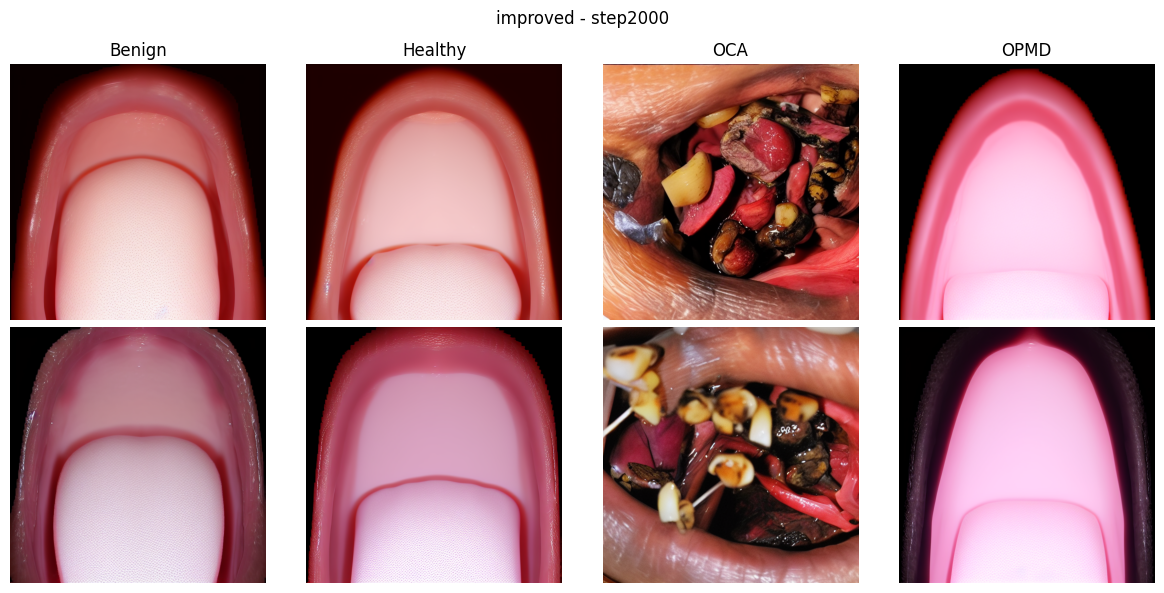

step  2050/3000  loss 0.1566  denoise 0.1223  contrast 0.6844  (106.1 min)
step  2100/3000  loss 0.1589  denoise 0.1249  contrast 0.6808  (109.1 min)
step  2150/3000  loss 0.1386  denoise 0.1057  contrast 0.6579  (112.1 min)
step  2200/3000  loss 0.1480  denoise 0.1135  contrast 0.6908  (115.1 min)
step  2250/3000  loss 0.1439  denoise 0.1094  contrast 0.6902  (118.1 min)
step  2300/3000  loss 0.1434  denoise 0.1101  contrast 0.6660  (121.0 min)
step  2350/3000  loss 0.1477  denoise 0.1150  contrast 0.6533  (124.0 min)
step  2400/3000  loss 0.1495  denoise 0.1166  contrast 0.6582  (127.0 min)
step  2450/3000  loss 0.1495  denoise 0.1167  contrast 0.6569  (130.0 min)
step  2500/3000  loss 0.1485  denoise 0.1145  contrast 0.6805  (132.9 min)
step  2550/3000  loss 0.1485  denoise 0.1162  contrast 0.6457  (135.9 min)
step  2600/3000  loss 0.1474  denoise 0.1142  contrast 0.6646  (138.8 min)
step  2650/3000  loss 0.1605  denoise 0.1283  contrast 0.6446  (141.8 min)
step  2700/3000  loss 0.1

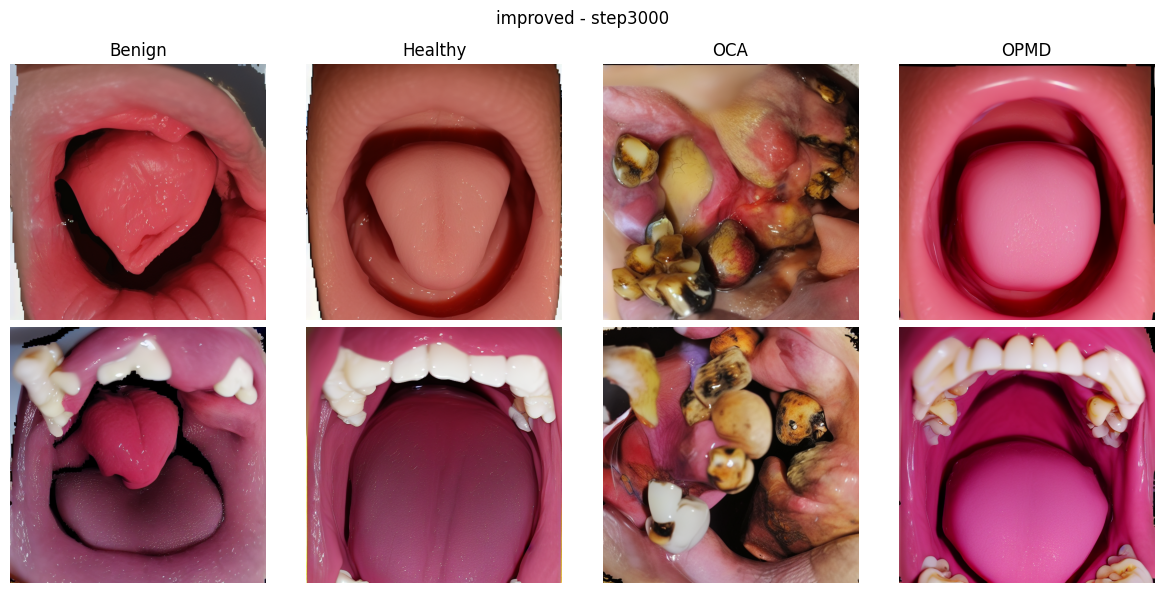

Done in 163.3 min. Final adapter saved to /kaggle/working/lora_oca_improved


In [9]:
# ============================================================
# 7. TRAINING LOOP
# ============================================================
rng = random.Random(SEED)
contrastive_start = int(CONTRASTIVE_START_FRAC * TRAIN_STEPS)
log_rows, buf = [], {"loss": [], "l_denoise": [], "l_contrast": []}
data_iter = iter(train_dl)
unet.train()
t0 = time.time()

for step in range(1, TRAIN_STEPS + 1):
    for _ in range(GRAD_ACCUM):
        pixels, labels = next(data_iter)
        pixels = pixels.to(DEVICE, dtype=torch.float32)
        bsz = pixels.shape[0]
        with torch.no_grad():
            latents = vae.encode(pixels).latent_dist.sample() * vae.config.scaling_factor
        noise = torch.randn_like(latents)
        t = torch.randint(0, noise_scheduler.config.num_train_timesteps, (bsz,), device=DEVICE).long()
        noisy = noise_scheduler.add_noise(latents, noise, t)
        target = noise if noise_scheduler.config.prediction_type == "epsilon" \
            else noise_scheduler.get_velocity(latents, noise, t)

        cls_names = [CLASSES[int(l)] for l in labels]
        dropped = [rng.random() < CAPTION_DROPOUT for _ in range(bsz)]
        pos_prompts = ["" if d else class_prompt(c) for c, d in zip(cls_names, dropped)]
        use_con = USE_CONTRASTIVE and step > contrastive_start and not all(dropped)

        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            if use_con:
                neg_prompts = [class_prompt(sample_negative_class(c, rng)) for c in cls_names]
                enc = encode_prompts(pos_prompts + neg_prompts, grad=USE_CLASS_TOKENS)
                pred = unet(torch.cat([noisy, noisy]), torch.cat([t, t]), encoder_hidden_states=enc).sample
                pred_pos, pred_neg = pred.float().chunk(2)
            else:
                enc = encode_prompts(pos_prompts, grad=USE_CLASS_TOKENS)
                pred_pos = unet(noisy, t, encoder_hidden_states=enc).sample.float()

        l_pos = F.mse_loss(pred_pos, target.float(), reduction="none").mean(dim=[1, 2, 3])
        loss = l_pos.mean()
        l_con = torch.zeros((), device=DEVICE)
        if use_con:
            l_neg = F.mse_loss(pred_neg, target.float(), reduction="none").mean(dim=[1, 2, 3])
            d = (l_pos - l_neg) / (l_pos.detach() + l_neg.detach() + 1e-8)
            mask = torch.tensor([not x for x in dropped], dtype=torch.float32, device=DEVICE)
            l_con = (F.softplus(d / CONTRASTIVE_TAU) * mask).sum() / mask.sum().clamp(min=1)
            loss = loss + CONTRASTIVE_WEIGHT * l_con
        scaler.scale(loss / GRAD_ACCUM).backward()
        buf["loss"].append(loss.item()); buf["l_denoise"].append(l_pos.mean().item()); buf["l_contrast"].append(l_con.item())

    if step == 1:   # sanity check: LoRA weights really receive gradients
        assert any(p.grad is not None and p.grad.abs().sum() > 0 for p in lora_params), "LoRA got no gradient!"
    if USE_CLASS_TOKENS:   # only the 4 class-token rows may change
        emb_w = text_encoder.get_input_embeddings().weight
        if emb_w.grad is not None:
            emb_w.grad[KEEP_FIXED] = 0
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(lora_params, 1.0)
    scaler.step(optimizer)
    scaler.update()
    optimizer.zero_grad(set_to_none=True)
    lr_sched.step()
    if USE_CLASS_TOKENS:
        with torch.no_grad():
            emb_w = text_encoder.get_input_embeddings().weight
            emb_w[KEEP_FIXED] = ORIG_EMB[KEEP_FIXED]

    if step % LOG_EVERY == 0 or step == TRAIN_STEPS:
        row = {"step": step, **{k: float(np.mean(v)) for k, v in buf.items()},
               "minutes": (time.time() - t0) / 60}
        log_rows.append(row)
        buf = {k: [] for k in buf}
        print(f"step {step:5d}/{TRAIN_STEPS}  loss {row['loss']:.4f}  denoise {row['l_denoise']:.4f}  "
              f"contrast {row['l_contrast']:.4f}  ({row['minutes']:.1f} min)")
    if step % SAVE_EVERY == 0 or step == TRAIN_STEPS:
        save_adapter(OUT_DIR / f"checkpoint-{step}")
        pd.DataFrame(log_rows).to_csv(OUT_DIR / "train_log.csv", index=False)
        preview(f"step{step}")

save_adapter(OUT_DIR)          # final weights at the top level of OUT_DIR
pd.DataFrame(log_rows).to_csv(OUT_DIR / "train_log.csv", index=False)
print(f"Done in {(time.time() - t0) / 60:.1f} min. Final adapter saved to {OUT_DIR}")

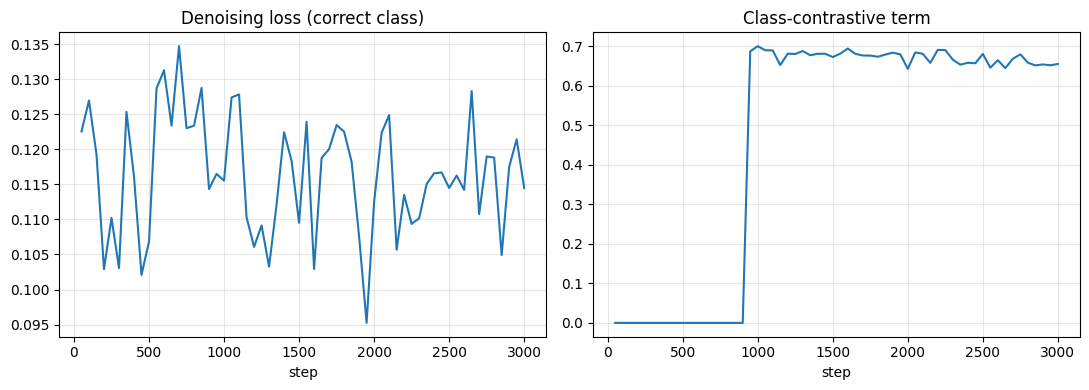

In [10]:
# ============================================================
# 8. TRAINING CURVES
# ============================================================
log_df = pd.DataFrame(log_rows)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(log_df.step, log_df.l_denoise); ax[0].set_title("Denoising loss (correct class)"); ax[0].set_xlabel("step")
ax[1].plot(log_df.step, log_df.l_contrast); ax[1].set_title("Class-contrastive term"); ax[1].set_xlabel("step")
for a in ax:
    a.grid(alpha=.3)
plt.tight_layout(); fig.savefig(OUT_DIR / "train_curves.png", dpi=130); plt.show()

## Notes
- **Outputs:** `unet_lora.pt`, `class_tokens.pt` (improved mode), `run_config.json`, `train_log.csv`,
  preview grids per checkpoint. Save the output as a Kaggle Dataset for notebook 03.
- **Check the preview grids**: OCA previews should look different from OPMD previews. If all four
  classes look the same, the class conditioning has not been learned (train longer / raise LoRA rank).
- **Memorisation:** OCA images are re-used many times (printed in section 4). If notebook 03 rejects many
  images as near-copies, use an *earlier* checkpoint (e.g. `checkpoint-2000`) or lower `CLASS_SAMPLING_PROBS["OCA"]`.
- **Ablation for the thesis:** re-run `MODE="improved"` with `USE_CONTRASTIVE=False` to separate the
  effect of the class tokens from the contrastive loss.